<a href="https://colab.research.google.com/github/Mahadeva77/DAV-Lab---4IK25CS097/blob/main/4ik25cs097_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

In [3]:
data = {
    "Study_Hours": [1, 2, 3, 4, 5, 6,
                    1, 2, 3, 4, 5, 6],

    "Result": [
        "Fail", "Fail", "Fail", "Fail", "Pass", "Pass",
        "Fail", "Fail", "Fail", "Pass", "Pass", "Pass"
    ]
}

df = pd.DataFrame(data)

In [4]:
print("STUDENT DATASET")
print(df)

STUDENT DATASET
    Study_Hours Result
0             1   Fail
1             2   Fail
2             3   Fail
3             4   Fail
4             5   Pass
5             6   Pass
6             1   Fail
7             2   Fail
8             3   Fail
9             4   Pass
10            5   Pass
11            6   Pass


In [5]:
X = df[["Study_Hours"]]
y = df["Result"]

# Step 4: Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

In [6]:
print("\nTraining Records:", len(X_train))
print("Testing Records:", len(X_test))

# Step 5: Create Logistic Regression Model
model = LogisticRegression()

# Step 6: Train the Model
model.fit(X_train, y_train)

print("\nModel Trained Successfully!")


Training Records: 9
Testing Records: 3

Model Trained Successfully!


In [7]:
print("\nLEARNED MODEL PARAMETERS")
print("Intercept:", model.intercept_[0])
print("Coefficient:", model.coef_[0][0])


LEARNED MODEL PARAMETERS
Intercept: -4.67287814115274
Coefficient: 1.3248119801450653


In [8]:
y_pred = model.predict(X_test)

print("\nACTUAL RESULTS:")
print(y_test.values)

print("\nPREDICTED RESULTS:")
print(y_pred)

# Step 9: Prediction Probabilities
y_prob = model.predict_proba(X_test)

print("\nPREDICTED PROBABILITIES:")
print(y_prob)


ACTUAL RESULTS:
['Pass' 'Fail' 'Fail']

PREDICTED RESULTS:
['Pass' 'Fail' 'Pass']

PREDICTED PROBABILITIES:
[[0.03640399 0.96359601]
 [0.6678423  0.3321577 ]
 [0.34833413 0.65166587]]


In [9]:
comparison = pd.DataFrame({
    "Study_Hours": X_test["Study_Hours"].values,
    "Actual_Result": y_test.values,
    "Predicted_Result": y_pred
})

print("\nACTUAL VS PREDICTED RESULTS")
print(comparison)


ACTUAL VS PREDICTED RESULTS
   Study_Hours Actual_Result Predicted_Result
0            6          Pass             Pass
1            3          Fail             Fail
2            4          Fail             Pass


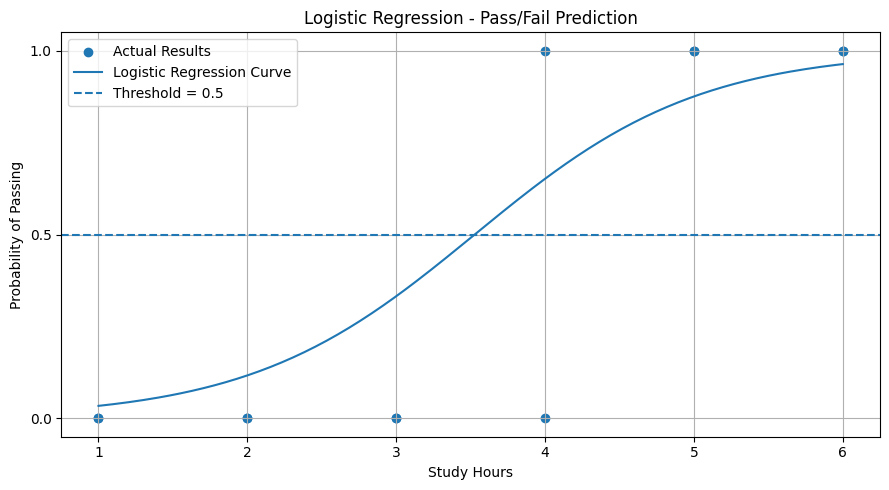

In [12]:
study_hours = pd.DataFrame({
    "Study_Hours": np.linspace(
        df["Study_Hours"].min(),
        df["Study_Hours"].max(),
        200
    )
})

pass_index = list(model.classes_).index("Pass")

probabilities = model.predict_proba(
    study_hours
)[:, pass_index]

plt.figure(figsize=(9, 5))

plt.scatter(
    df["Study_Hours"],
    df["Result"].map({"Fail": 0, "Pass": 1}),
    label="Actual Results"
)

plt.plot(
    study_hours["Study_Hours"],
    probabilities,
    label="Logistic Regression Curve"
)

plt.axhline(
    y=0.5,
    linestyle="--",
    label="Threshold = 0.5"
)

plt.xlabel("Study Hours")
plt.ylabel("Probability of Passing")
plt.title("Logistic Regression - Pass/Fail Prediction")
plt.yticks([0, 0.5, 1])
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [13]:
accuracy = accuracy_score(y_test, y_pred)

print("\nMODEL EVALUATION METRICS")
print("Accuracy:", accuracy * 100, "%")


MODEL EVALUATION METRICS
Accuracy: 66.66666666666666 %



CONFUSION MATRIX
[[1 1]
 [0 1]]


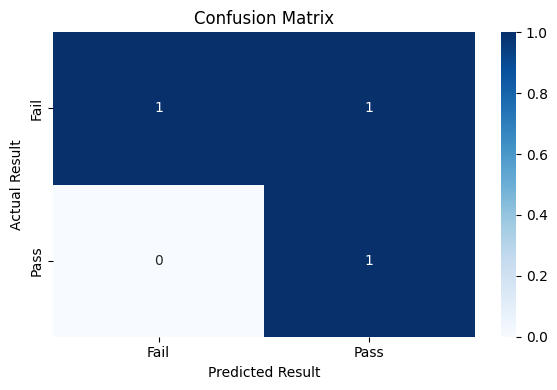

In [14]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Fail", "Pass"]
)

print("\nCONFUSION MATRIX")
print(cm)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fail", "Pass"],
    yticklabels=["Fail", "Pass"]
)

plt.xlabel("Predicted Result")
plt.ylabel("Actual Result")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

In [16]:
from sklearn.metrics import precision_score

precision = precision_score(
    y_test,
    y_pred,
    pos_label="Pass",
    zero_division=0
)

print("\nPrecision:", precision)


Precision: 0.5


In [17]:
recall = recall_score(
    y_test, y_pred,
    pos_label="Pass",
    zero_division=0
)

print("Recall:", recall)

Recall: 1.0


In [18]:
f1 = f1_score(
    y_test, y_pred,
    pos_label="Pass",
    zero_division=0
)

print("F1-Score:", f1)

F1-Score: 0.6666666666666666


In [19]:
print("\nCLASSIFICATION REPORT")

print(classification_report(
    y_test,
    y_pred,
    labels=["Fail", "Pass"],
    zero_division=0
))


CLASSIFICATION REPORT
              precision    recall  f1-score   support

        Fail       1.00      0.50      0.67         2
        Pass       0.50      1.00      0.67         1

    accuracy                           0.67         3
   macro avg       0.75      0.75      0.67         3
weighted avg       0.83      0.67      0.67         3



In [20]:
new_student = pd.DataFrame({
    "Study_Hours": [5]
})

prediction = model.predict(new_student)
probability = model.predict_proba(new_student)

print("\nNEW STUDENT DETAILS")
print(new_student)

print("Probability of Fail:", probability[0][0])
print("Probability of Pass:", probability[0][1])

print("\nPREDICTED STUDENT RESULT:", prediction[0])


NEW STUDENT DETAILS
   Study_Hours
0            5
Probability of Fail: 0.12442455650005035
Probability of Pass: 0.8755754434999496

PREDICTED STUDENT RESULT: Pass


In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [22]:
data = {
    "Study_Hours": [1, 2, 4, 5, 1, 2, 4, 5],
    "Attendance": [50, 60, 65, 70, 80, 85, 90, 95],
    "Result": [
        "Fail", "Fail", "Fail", "Fail",
        "Pass", "Pass", "Pass", "Pass"
    ]
}

df = pd.DataFrame(data)

print("STUDENT DATASET:")
print(df)

STUDENT DATASET:
   Study_Hours  Attendance Result
0            1          50   Fail
1            2          60   Fail
2            4          65   Fail
3            5          70   Fail
4            1          80   Pass
5            2          85   Pass
6            4          90   Pass
7            5          95   Pass


In [23]:
X = df[["Study_Hours", "Attendance"]]
y = df["Result"]

# Step 4: Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("\nTraining Records:")
print(len(X_train))

print("\nTesting Records:")
print(len(X_test))

# Step 5: Create Decision Tree Classifier
model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=2,
    random_state=42
)


Training Records:
6

Testing Records:
2



Decision Tree Model Trained Successfully!


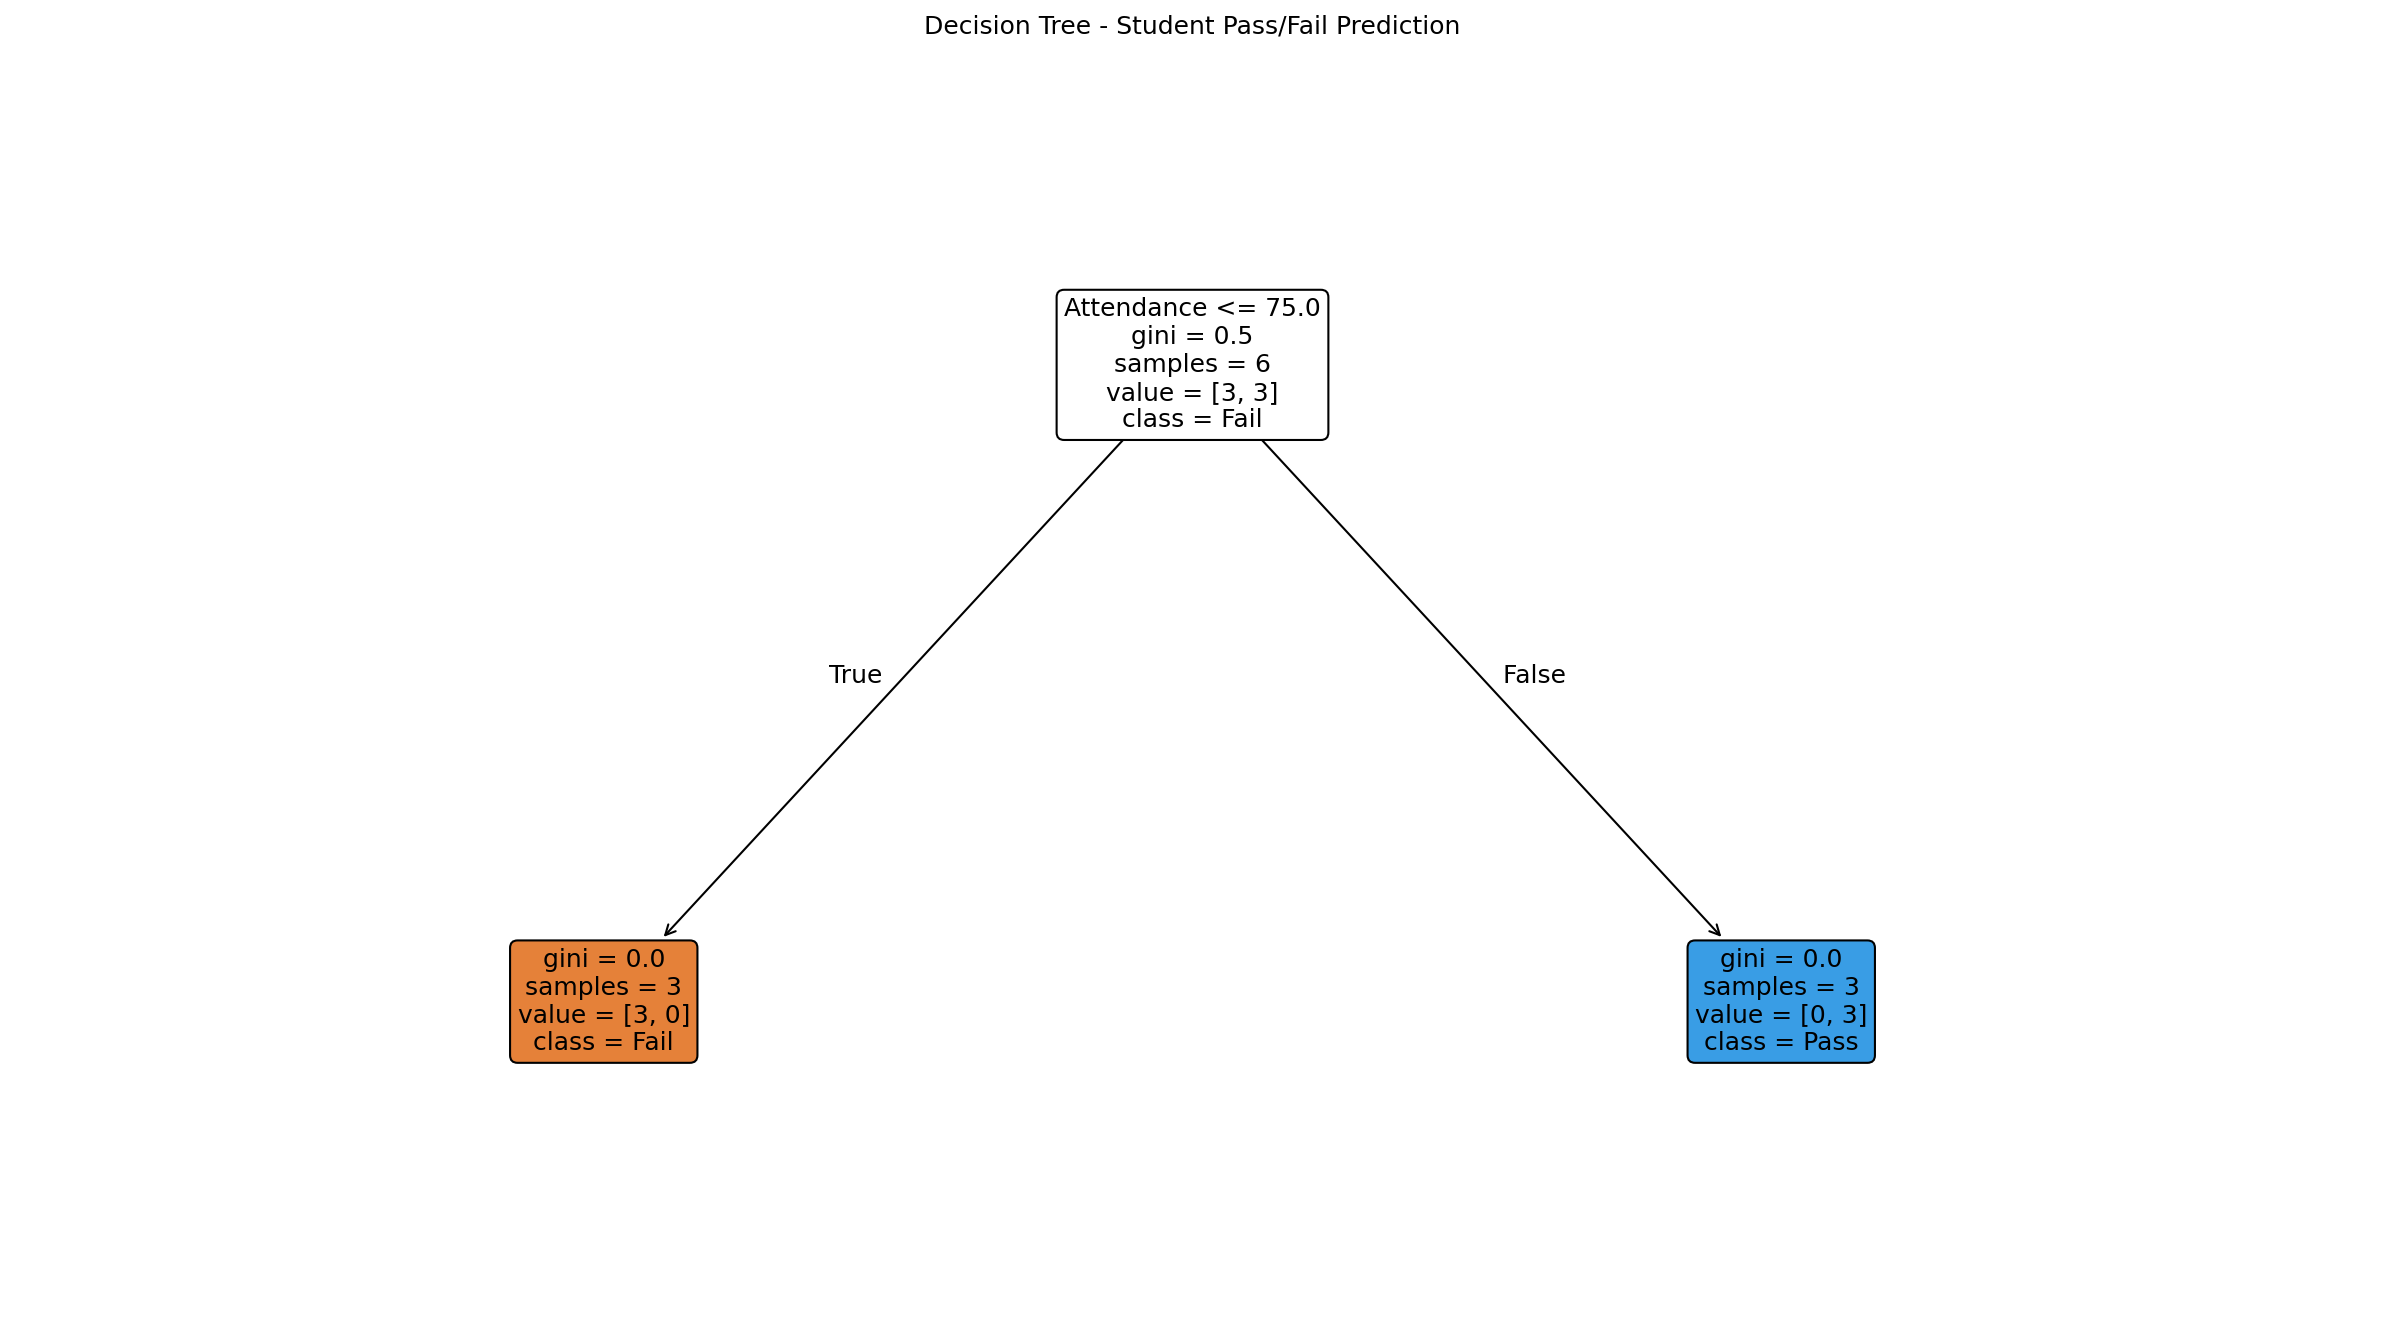

In [24]:
model.fit(X_train, y_train)

print("\nDecision Tree Model Trained Successfully!")

# Step 7: Visualize Decision Tree
plt.figure(figsize=(16, 9), dpi=150)

plot_tree(
    model,
    feature_names=["Study Hours", "Attendance"],
    class_names=["Fail", "Pass"],
    filled=True,
    rounded=True,
    proportion=False,
    precision=2,
    fontsize=12
)

plt.title("Decision Tree - Student Pass/Fail Prediction")
plt.tight_layout()
plt.show()

In [25]:
y_pred = model.predict(X_test)

print("\nActual Results:")
print(y_test.values)

print("\nPredicted Results:")
print(y_pred)

# Step 9: Calculate Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("\nModel Accuracy:", accuracy * 100, "%")


Actual Results:
['Fail' 'Pass']

Predicted Results:
['Fail' 'Pass']

Model Accuracy: 100.0 %



CONFUSION MATRIX:
[[1 0]
 [0 1]]


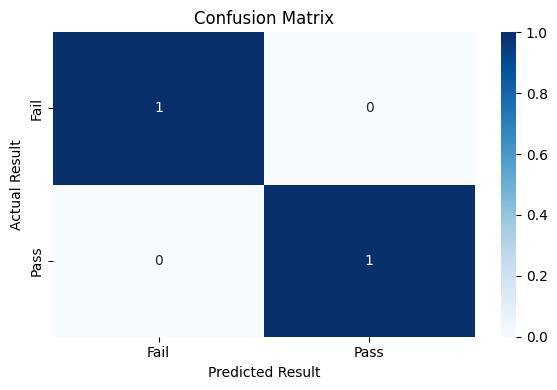

In [26]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Fail", "Pass"]
)

print("\nCONFUSION MATRIX:")
print(cm)

# Visualize Confusion Matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fail", "Pass"],
    yticklabels=["Fail", "Pass"]
)

plt.xlabel("Predicted Result")
plt.ylabel("Actual Result")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

In [27]:
print("\nCLASSIFICATION REPORT:")

print(classification_report(
    y_test,
    y_pred,
    labels=["Fail", "Pass"],
    zero_division=0
))


CLASSIFICATION REPORT:
              precision    recall  f1-score   support

        Fail       1.00      1.00      1.00         1
        Pass       1.00      1.00      1.00         1

    accuracy                           1.00         2
   macro avg       1.00      1.00      1.00         2
weighted avg       1.00      1.00      1.00         2



In [28]:
new_student = pd.DataFrame({
    "Study_Hours": [4],
    "Attendance": [85]
})

prediction = model.predict(new_student)

print("\nNEW STUDENT DETAILS:")
print(new_student)

print("\nPREDICTED STUDENT RESULT:")
print(prediction[0])


NEW STUDENT DETAILS:
   Study_Hours  Attendance
0            4          85

PREDICTED STUDENT RESULT:
Pass


In [29]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from matplotlib.patches import Circle

In [30]:
data = {
    "Student": ['A', 'B', 'C', 'D', 'E', 'F'],
    "StudyHours": [1, 2, 3, 8, 9, 10],
    "Marks": [30, 35, 40, 80, 85, 90]
}

df = pd.DataFrame(data)

print("STUDENT DATASET:")
print(df)

STUDENT DATASET:
  Student  StudyHours  Marks
0       A           1     30
1       B           2     35
2       C           3     40
3       D           8     80
4       E           9     85
5       F          10     90


In [31]:
X = df[['StudyHours', 'Marks']]

# Step 4: Apply K-Means Clustering
kmeans = KMeans(
    n_clusters=2,
    init='random',
    random_state=42,
    n_init=10
)

df['Cluster'] = kmeans.fit_predict(X)

print("\nSTUDENT GROUPS:")
print(df)


STUDENT GROUPS:
  Student  StudyHours  Marks  Cluster
0       A           1     30        0
1       B           2     35        0
2       C           3     40        0
3       D           8     80        1
4       E           9     85        1
5       F          10     90        1



FINAL CENTROIDS:
[[ 2. 35.]
 [ 9. 85.]]


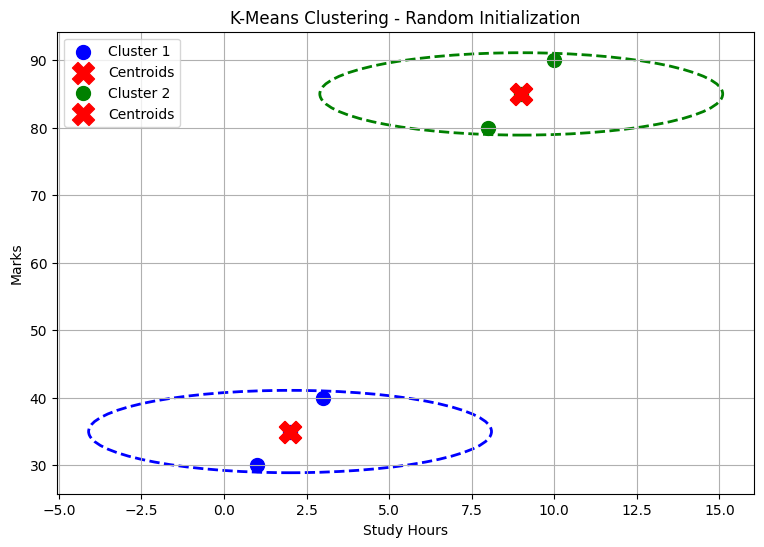

In [34]:
centroids = kmeans.cluster_centers_

print("\nFINAL CENTROIDS:")
print(centroids)

# Step 6: Visualize Two Clusters
plt.figure(figsize=(9, 6))

colors = ['blue', 'green']

for cluster in range(2):

    cluster_data = df[df['Cluster'] == cluster]

    plt.scatter(
        cluster_data['StudyHours'],
        cluster_data['Marks'],
        color=colors[cluster],
        s=100,
        label=f'Cluster {cluster + 1}'
    )

    center_x = centroids[cluster, 0]
    center_y = centroids[cluster, 1]

    distances = (
        (cluster_data['StudyHours'] - center_x)**2 +
        (cluster_data['Marks'] - center_y)**2
    )**0.5

    radius = distances.max() + 1

    circle = Circle(
        (center_x, center_y),
        radius,
        fill=False,
        color=colors[cluster],
        linewidth=2,
        linestyle='--'
    )

    plt.gca().add_patch(circle)
    plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    color='red',
    marker='X',
    s=250,
    label='Centroids'
)

plt.xlabel('Study Hours')
plt.ylabel('Marks')
plt.title('K-Means Clustering - Random Initialization')
plt.legend()
plt.grid(True)
plt.show()

In [35]:
wcss = []

for k in range(1, 7):

    model = KMeans(
        n_clusters=k,
        init='random',
        random_state=42,
        n_init=10
    )

    model.fit(X)

    wcss.append(model.inertia_)

print("\nWCSS VALUES:")

for k, value in enumerate(wcss, start=1):
    print(f"K = {k}, WCSS = {value:.2f}")


WCSS VALUES:
K = 1, WCSS = 3927.50
K = 2, WCSS = 104.00
K = 3, WCSS = 65.00
K = 4, WCSS = 26.00
K = 5, WCSS = 13.00
K = 6, WCSS = 0.00


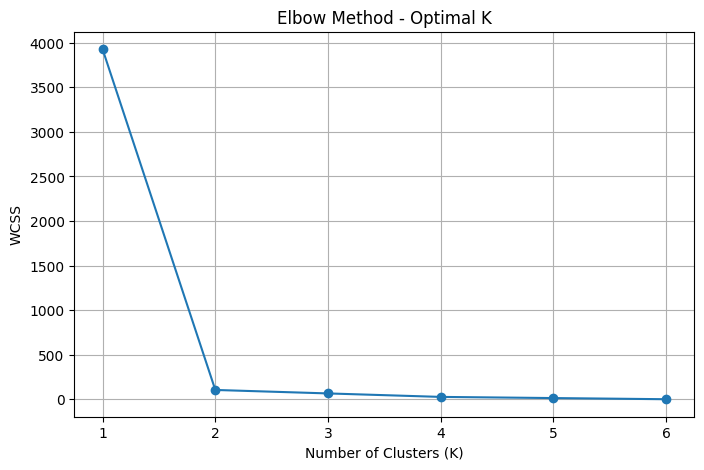

In [36]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 7),
    wcss,
    marker='o',
    linestyle='-'
)

plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.title('Elbow Method - Optimal K')
plt.xticks(range(1, 7))
plt.grid(True)
plt.show()

In [37]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from scipy.cluster.hierarchy import dendrogram

In [38]:
students = ['A', 'B', 'C', 'D', 'E', 'F']

marks = [30, 35, 40, 80, 85, 90]

x = np.arange(len(students))
marks_array = np.array(marks)

In [39]:
phases = [
    [[0], [1], [2], [3], [4], [5]],

    [[0, 1], [2], [3], [4], [5]],

    [[0, 1, 2], [3], [4], [5]],

    [[0, 1, 2], [3, 4], [5]],

    [[0, 1, 2], [3, 4, 5]],

    [[0, 1, 2, 3, 4, 5]]
]

titles = [
    "Phase 1: Initial 6 Clusters",
    "Phase 2: Merge A and B",
    "Phase 3: Merge C with AB",
    "Phase 4: Merge D and E",
    "Phase 5: Merge F with DE",
    "Phase 6: Merge ABC and DEF"
]

colors = [
    "blue", "orange", "green",
    "red", "purple", "brown"
]

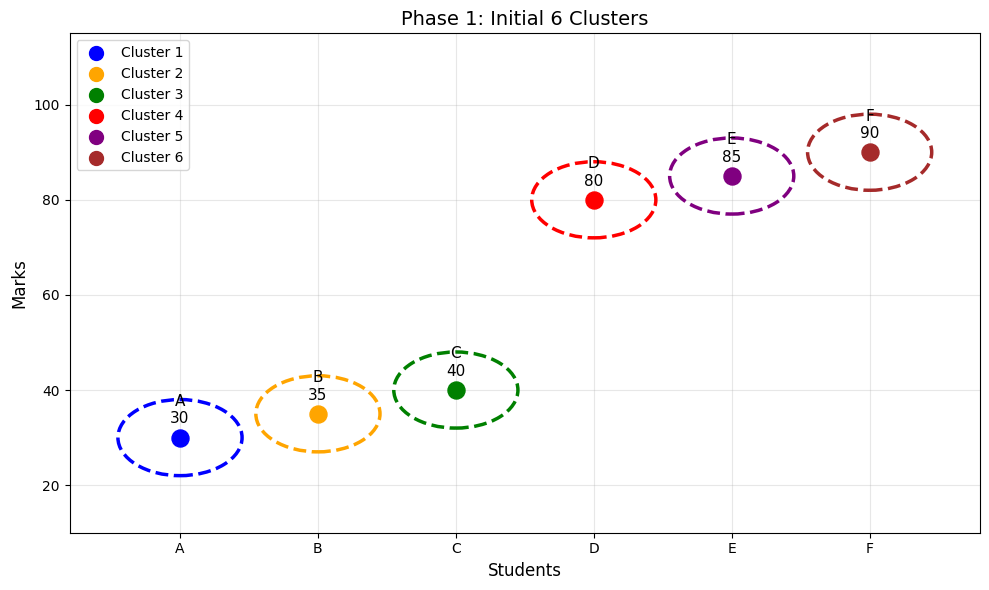

<Figure size 1200x700 with 0 Axes>

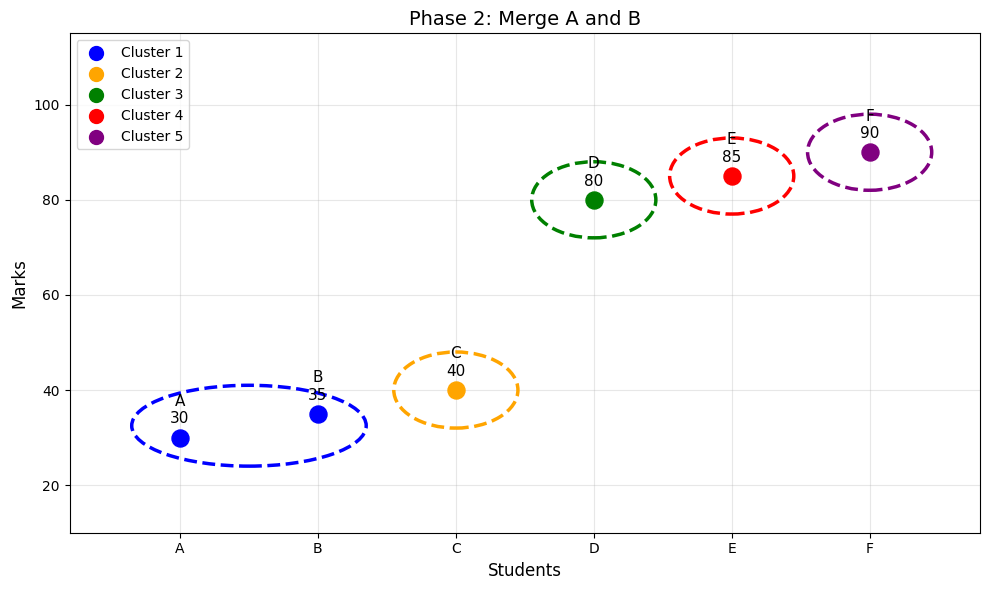

<Figure size 1200x700 with 0 Axes>

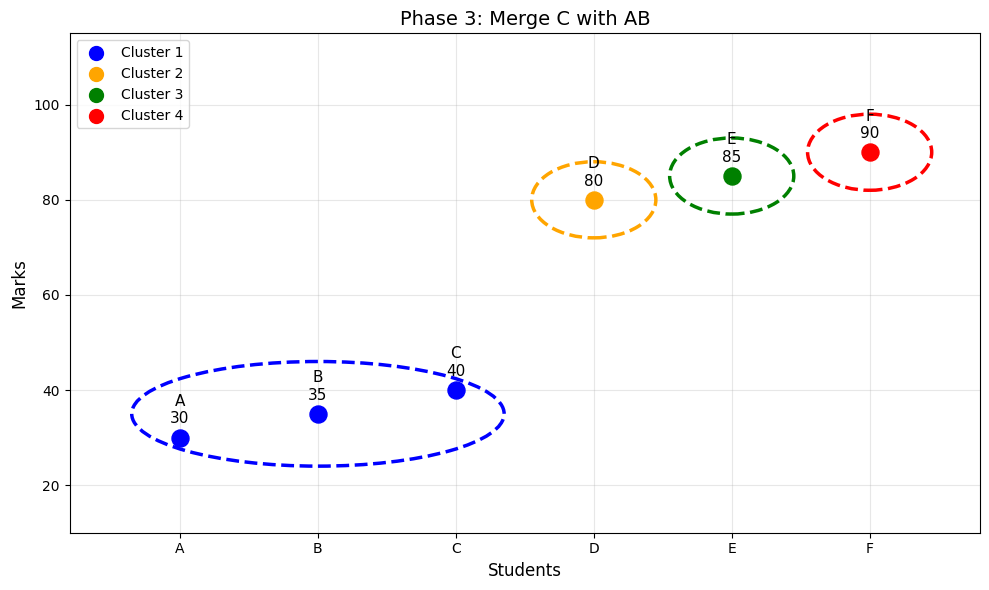

<Figure size 1200x700 with 0 Axes>

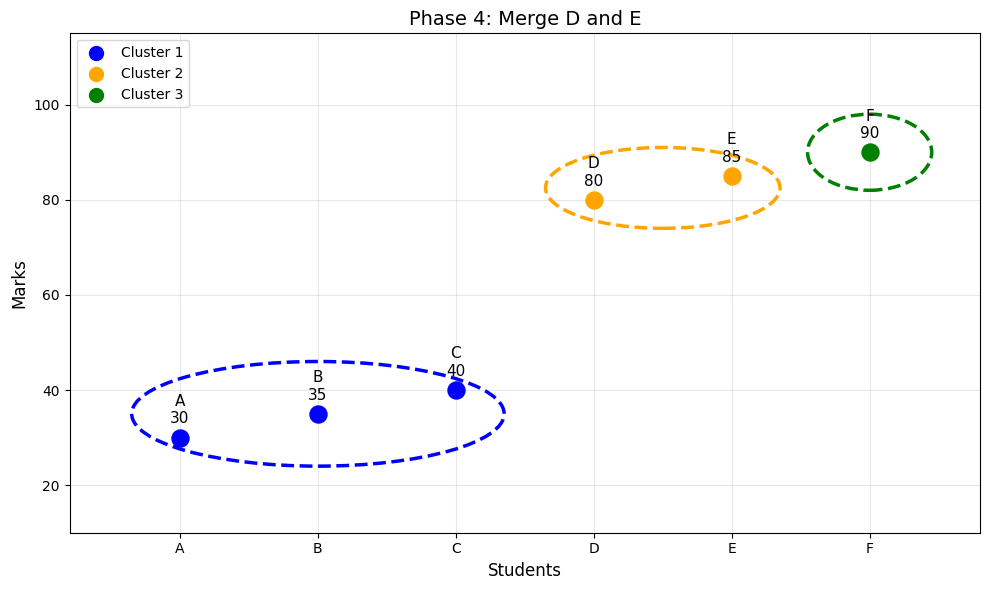

<Figure size 1200x700 with 0 Axes>

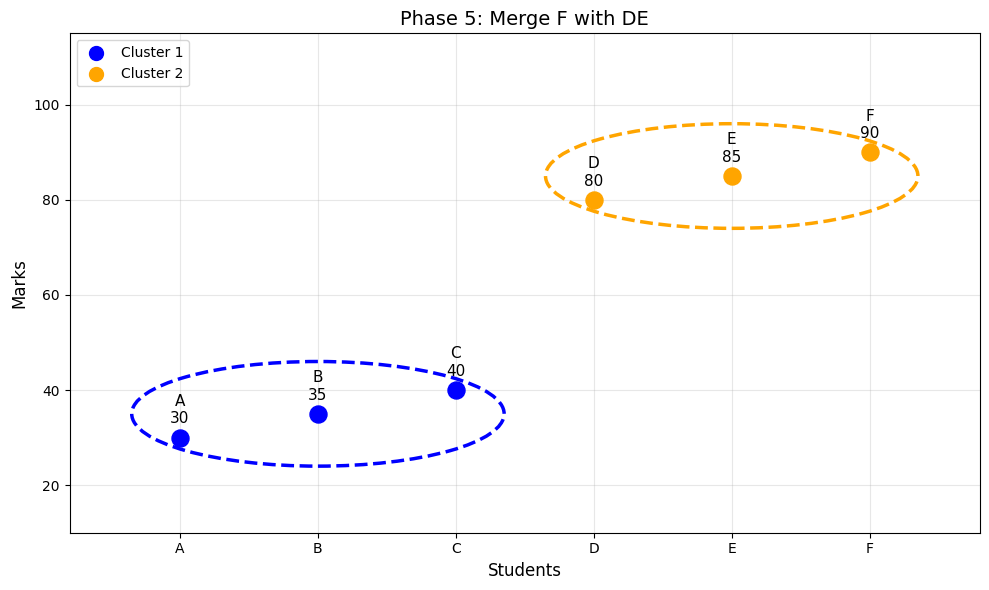

<Figure size 1200x700 with 0 Axes>

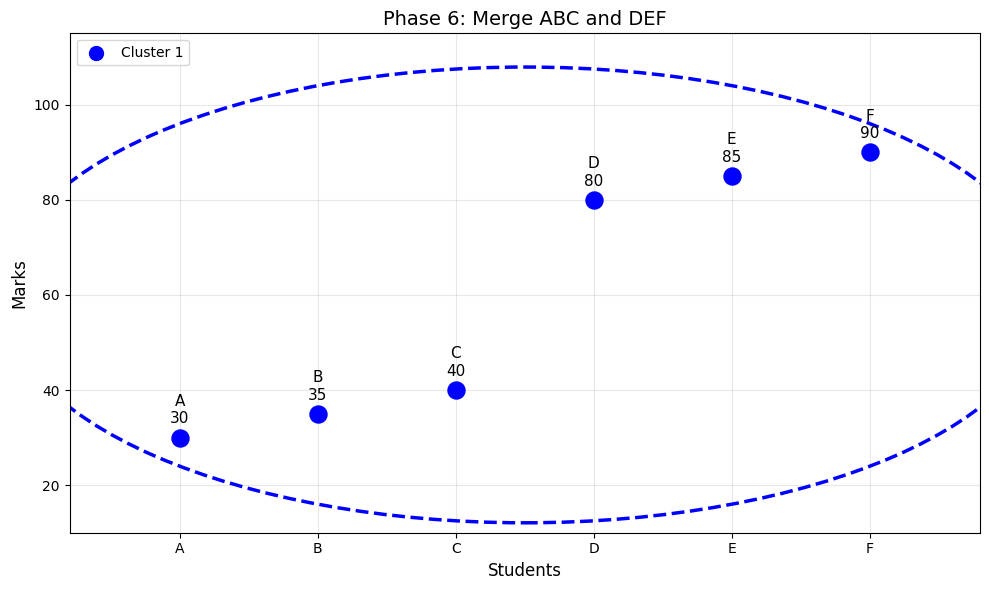

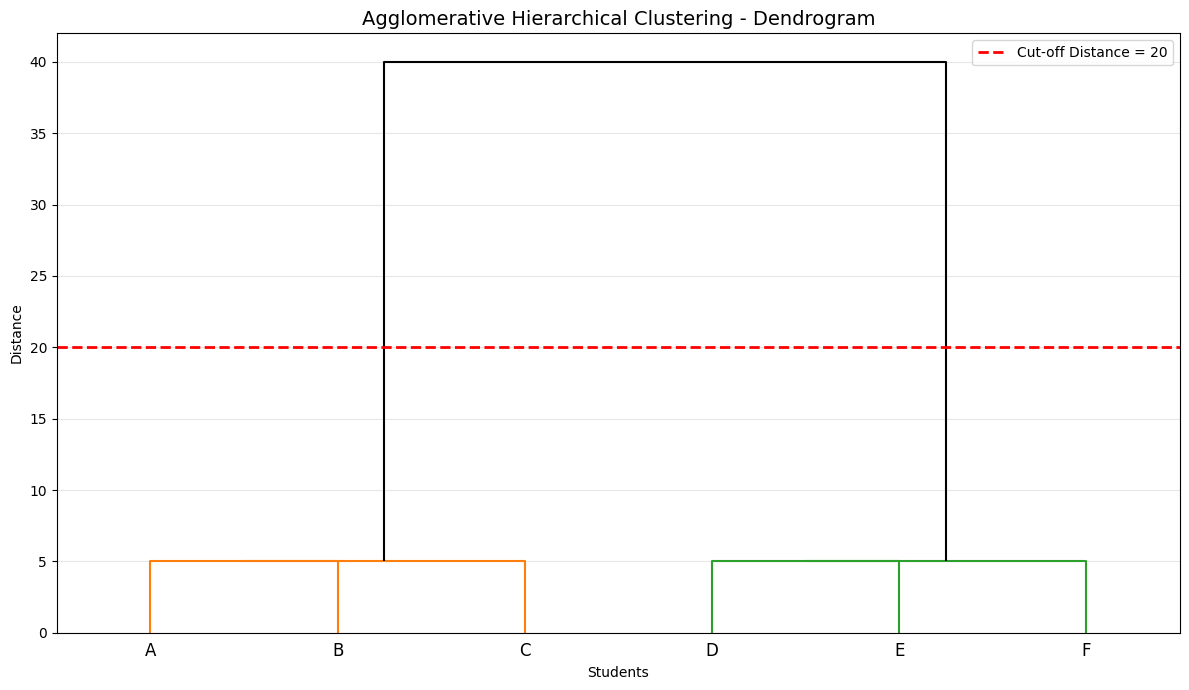

In [43]:
for phase_no, clusters in enumerate(phases):

    fig, ax = plt.subplots(figsize=(10, 6))

    for cluster_no, cluster in enumerate(clusters):

        color = colors[cluster_no]

        cluster_x = x[cluster]
        cluster_y = marks_array[cluster]

        # Plot Students
        ax.scatter(
            cluster_x,
            cluster_y,
            color=color,
            s=150,
            zorder=3
        )

        # Display Student Names and Marks
        for i in cluster:

            ax.text(
                x[i],
                marks[i] + 3,
                f"{students[i]}\n{marks[i]}",
                ha='center',
                fontsize=11
            )

        # Calculate Ellipse Centre
        center_x = np.mean(cluster_x)
        center_y = np.mean(cluster_y)

        # Calculate Ellipse Radius
        radius_x = max(
            np.max(np.abs(cluster_x - center_x)) + 0.35,
            0.45
        )

        radius_y = max(
            np.max(np.abs(cluster_y - center_y)) + 6,
            8
        )

        distances = np.sqrt(
            ((cluster_x - center_x) / radius_x) ** 2 +
            ((cluster_y - center_y) / radius_y) ** 2
        )

        scale = max(
            1.0,
            np.max(distances) * 1.10
        )

        radius_x *= scale
        radius_y *= scale

        # Draw Ellipse
        ellipse = Ellipse(
            (center_x, center_y),
            width=2 * radius_x,
            height=2 * radius_y,
            edgecolor=color,
            facecolor='none',
            linewidth=2.5,
            linestyle='--',
            zorder=2
        )

        ax.add_patch(ellipse)

        # Legend
        ax.scatter(
            [],
            [],
            color=color,
            s=100,
            label=f"Cluster {cluster_no + 1}"
        )

    # Graph Formatting
    ax.set_title(titles[phase_no], fontsize=14)
    ax.set_xlabel("Students", fontsize=12)
    ax.set_ylabel("Marks", fontsize=12)

    ax.set_xticks(x)
    ax.set_xticklabels(students)

    ax.set_xlim(-0.8, 5.8)
    ax.set_ylim(10, 115)

    ax.grid(True, alpha=0.3)
    ax.legend(loc='upper left')

    plt.tight_layout()
    plt.show()

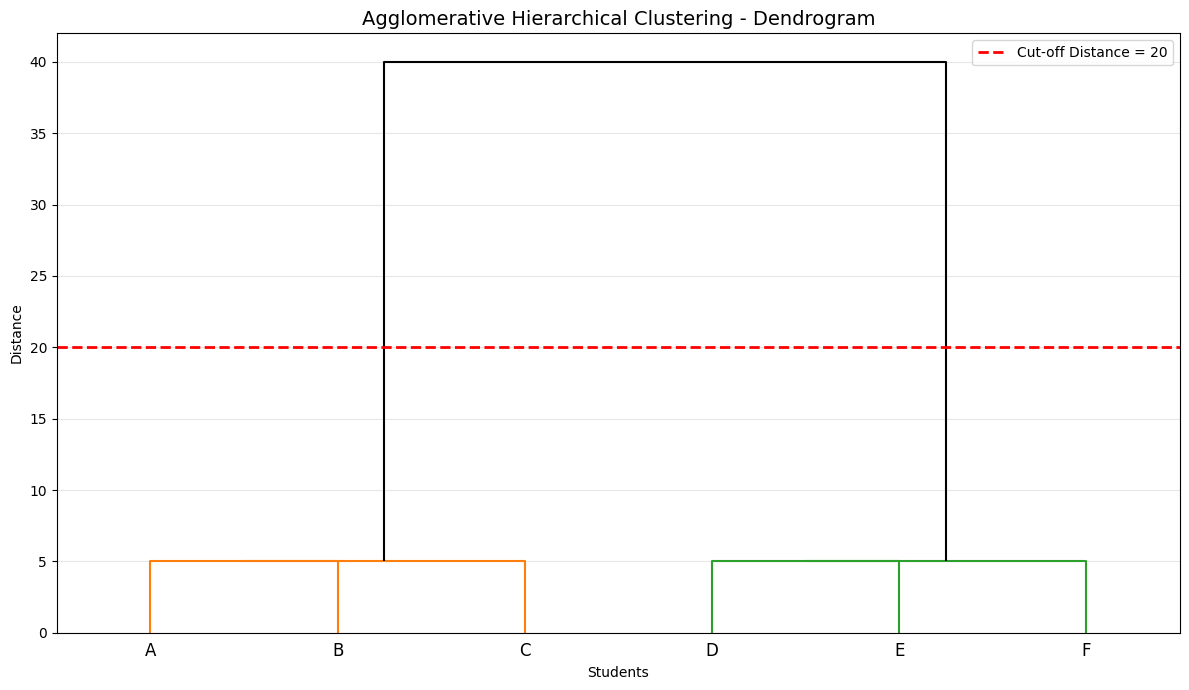

In [44]:
Z = np.array([
    [0, 1, 5, 2],    # A + B
    [6, 2, 5, 3],    # AB + C
    [3, 4, 5, 2],    # D + E
    [8, 5, 5, 3],    # DE + F
    [7, 9, 40, 6]    # ABC + DEF
], dtype=np.float64)
plt.figure(figsize=(12, 7))

dendrogram(
    Z,
    labels=students,
    color_threshold=20,
    above_threshold_color='black'
)

plt.axhline(
    y=20,
    color='red',
    linestyle='--',
    linewidth=2,
    label='Cut-off Distance = 20'
)

plt.title(
    "Agglomerative Hierarchical Clustering - Dendrogram",
    fontsize=14
)

plt.xlabel("Students")
plt.ylabel("Distance")

plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()